# Challenge 2: Neural Network

Predict `Revenue` (did the visit end in a purchase?) with a neural network, scikit-learn's `MLPClassifier`.

1. Load the data and make the same split as `challenge2_validation_split.ipynb` (same seed, so the same rows).
2. Prepare the features. Neural networks need every input on a similar scale.
3. Score a baseline and a default network.
4. Tune the network's size and regularization with grid search on the 5 folds.
5. Pick the decision threshold that gives the best F1.
6. Evaluation charts: model comparison, tuning, ROC and precision-recall curves, threshold, confusion matrices, probabilities, calibration, learning curve, training curve, and feature importance.

The 20% hold-out is **not** used here. It gets scored once, after the team compares all models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (make_scorer, f1_score, precision_score, recall_score, confusion_matrix,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42

In [2]:
# chart style used by every figure below
NAVY, ORANGE, TEAL, RED, GRAY = "#1f3b73", "#f28e2b", "#2a9d8f", "#d1495b", "#9aa0a6"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "font.size": 10,
})

## Load and split

Same code and seed as `challenge2_validation_split.ipynb`, so these are the same training rows, hold-out rows and folds.

In [3]:
train = pd.read_csv("challenge2_train.csv")

def to_01(col):
    """Turn True/False (bool or text) into 1/0."""
    if col.dtype == bool:
        return col.astype(int)
    return col.astype(str).str.strip().str.lower().map({"true": 1, "false": 0})

y = to_01(train["Revenue"])
X = train.drop(columns=["ID", "Revenue"]).copy()
X["Weekend"] = to_01(X["Weekend"])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
BUYER_SHARE = y_train.mean()

print(f"Training rows: {len(X_train):,} ({BUYER_SHARE:.1%} buyers)")
print(f"Hold-out rows: {len(X_val):,} (not used in this notebook)")

Training rows: 7,397 (15.5% buyers)
Hold-out rows: 1,850 (not used in this notebook)


## Prepare the features

A neural network adds up weighted inputs, so a column measured in thousands of seconds would drown out one between 0 and 1. Everything goes through `StandardScaler`.

- **Long-tailed columns** (page counts, durations, `PageValues`): most visits are near zero and a few are huge. Taking `log(1 + x)` first pulls in the long tail so a few extreme visits don't dominate.
- **Rates** (`BounceRates`, `ExitRates`, `SpecialDay`): already between 0 and 1, so just scaled.
- **Category codes** (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`): one-hot encoded. `Browser 4` is not "twice" `Browser 2`.
- **`Weekend`**: already 0/1.

All of this sits inside the pipeline, so it is fitted on each fold's training rows only.

In [4]:
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "PageValues"]
rate_cols = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
bin_cols = ["Weekend"]

assert set(log_cols + rate_cols + cat_cols + bin_cols) == set(X.columns)

preprocessor = ColumnTransformer([
    ("log", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), log_cols),
    ("rate", StandardScaler(), rate_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

print("Inputs to the network:", preprocessor.fit_transform(X_train).shape[1])

Inputs to the network: 72


## How models are scored

Only 15.5% of visits are purchases, so accuracy is misleading. The main score is **F1** (balances catching buyers against false alarms). Also reported:

- **ROC-AUC** and **PR-AUC**: how well the model ranks buyers above non-buyers, before any threshold is picked.
- **Recall**: share of real buyers caught. **Precision**: share of predicted buyers who really bought.
- **Train F1 and the gap**: a big gap between training and CV F1 means overfitting.

In [5]:
scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "accuracy": "accuracy",
}

def evaluate(name, model):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
        row[f"{m} std"] = res[f"test_{m}"].std()
    row["train f1"] = res["train_f1"].mean()
    row["f1 gap"] = row["train f1"] - row["f1"]
    return row

SHOW = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy", "train f1", "f1 gap"]

results = [
    evaluate("Baseline (always 'no purchase')", DummyClassifier(strategy="most_frequent")),
    evaluate("Neural network, default", MLPClassifier(max_iter=500, early_stopping=True,
                                                      random_state=RANDOM_STATE)),
]
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"Neural network, default",0.637,0.928,0.730,0.573,0.722,0.900,0.658,0.022


## Tune the network

Settings searched:
- **`hidden_layer_sizes`**: how many neurons, in one or two layers. More neurons can learn more but also memorize more.
- **`alpha`**: L2 penalty on the weights. Higher means a simpler, smoother model.
- **`learning_rate_init`**: step size during training.

`early_stopping=True` holds back 10% of each fold's training rows and stops when the score there stops improving, which also guards against overfitting.

The search ranks settings by **ROC-AUC**, not F1. F1 depends on the 0.5 threshold, which is the wrong cut-off for rare buyers (fixed further down). ROC-AUC scores the ranking itself.

In [6]:
nn_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE)),
])

param_grid = {
    "model__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16)],
    "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 3.0, 10.0],
    "model__learning_rate_init": [1e-3, 1e-2, 3e-2],
}

search = GridSearchCV(nn_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)

best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best settings:", best_params)
print(f"Best CV ROC-AUC: {search.best_score_:.3f}")

Best settings: {'alpha': 1.0, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.01}
Best CV ROC-AUC: 0.932


In [7]:
grid = pd.DataFrame(search.cv_results_)
grid["hidden layers"] = grid["param_model__hidden_layer_sizes"].astype(str)
grid["alpha"] = grid["param_model__alpha"].astype(float)
grid["learning rate"] = grid["param_model__learning_rate_init"].astype(float)

grid.sort_values("rank_test_score").head(10)[
    ["hidden layers", "alpha", "learning rate", "mean_test_score", "mean_train_score"]
].rename(columns={"mean_test_score": "CV ROC-AUC", "mean_train_score": "train ROC-AUC"}).round(4).reset_index(drop=True)

,hidden layers,alpha,learning rate,CV ROC-AUC,train ROC-AUC
0,"(32, 16)",1.0000,0.01,0.9323,0.9410
1,"(32, 16)",0.1000,0.03,0.9321,0.9482
2,"(64,)",0.0100,0.01,0.9319,0.9520
3,"(32,)",0.1000,0.01,0.9318,0.9502
4,"(16,)",0.1000,0.03,0.9310,0.9479
5,"(16,)",0.1000,0.01,0.9309,0.9439
6,"(16,)",0.0100,0.01,0.9308,0.9447
7,"(16,)",0.0010,0.01,0.9306,0.9465
8,"(64,)",0.1000,0.01,0.9305,0.9502
9,"(16,)",0.0001,0.01,0.9299,0.9441


In [8]:
best_nn = MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE, **best_params)
best_pipe = Pipeline([("prep", preprocessor), ("model", best_nn)])

results.append(evaluate("Neural network, tuned", best_nn))
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"Neural network, default",0.637,0.928,0.730,0.573,0.722,0.900,0.658,0.022
"Neural network, tuned",0.674,0.932,0.751,0.656,0.696,0.902,0.697,0.022


## Out-of-fold predictions

Every training row gets a purchase probability from a model that did **not** train on it: for each of the 5 folds, train on the other 4 and predict that fold. All charts below and the threshold choice use these predictions, never the hold-out.

In [9]:
oof_proba = np.zeros(len(y_train))
fold_id = np.zeros(len(y_train), dtype=int)
fold_models = []

for k, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    m = clone(best_pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof_proba[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    fold_id[va] = k
    fold_models.append((m, va))

y_true = y_train.to_numpy()
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_true, oof_proba):.3f}")
print(f"Out-of-fold PR-AUC:  {average_precision_score(y_true, oof_proba):.3f}")

Out-of-fold ROC-AUC: 0.930
Out-of-fold PR-AUC:  0.746


## Pick the decision threshold

The network outputs a probability of purchase. By default anything at 0.5 or above counts as "buyer". With only 15.5% buyers, many real buyers sit below 0.5, so a lower cut-off usually gives a better F1. Every threshold from 0.05 to 0.95 is tried on the out-of-fold predictions and the best F1 is kept.

The tuned threshold is picked and scored on the same predictions, so its F1 is slightly optimistic. The hold-out score at the end will be the honest number.

In [10]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame({
    "threshold": thresholds,
    "f1": [f1_score(y_true, oof_proba >= t) for t in thresholds],
    "precision": [precision_score(y_true, oof_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_true, oof_proba >= t) for t in thresholds],
})
best_threshold = curve.loc[curve["f1"].idxmax(), "threshold"]

def scores_at(t):
    pred = oof_proba >= t
    return {"threshold": t, "f1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "accuracy": (pred == y_true).mean()}

pd.DataFrame([scores_at(0.5), scores_at(best_threshold)], index=["default", "tuned"]).round(3)

,threshold,f1,precision,recall,accuracy
default,0.50,0.675,0.695,0.656,0.902
tuned,0.38,0.694,0.645,0.751,0.897


---
# Evaluation charts

### 1. Model comparison

Accuracy (far right) is the trap: the baseline that never predicts a purchase already scores about 85%. The other scores show the real difference. Error bars are the spread across the 5 folds.

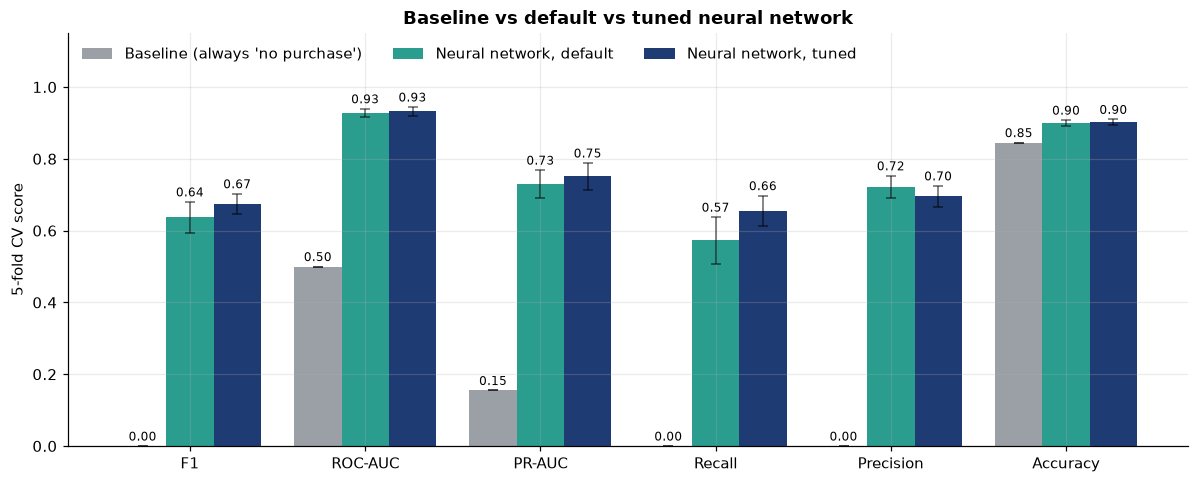

In [11]:
res = pd.DataFrame(results).set_index("model")
metrics = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy"]
labels = ["F1", "ROC-AUC", "PR-AUC", "Recall", "Precision", "Accuracy"]
colors = [GRAY, TEAL, NAVY]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(metrics))
w = 0.27
for i, (name, row) in enumerate(res.iterrows()):
    vals = [row[m] for m in metrics]
    errs = [row[f"{m} std"] for m in metrics]
    bars = ax.bar(x + (i - 1) * w, vals, w, yerr=errs, capsize=3, color=colors[i], label=name,
                  error_kw={"elinewidth": 1, "alpha": 0.6})
    for b, v, e in zip(bars, vals, errs):
        ax.text(b.get_x() + b.get_width() / 2, v + e + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("5-fold CV score")
ax.set_title("Baseline vs default vs tuned neural network")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

### 2. Tuning results

Each cell is the CV ROC-AUC for one network size and one `alpha`, at the best learning rate. Dark is better. The black box is the setting chosen.

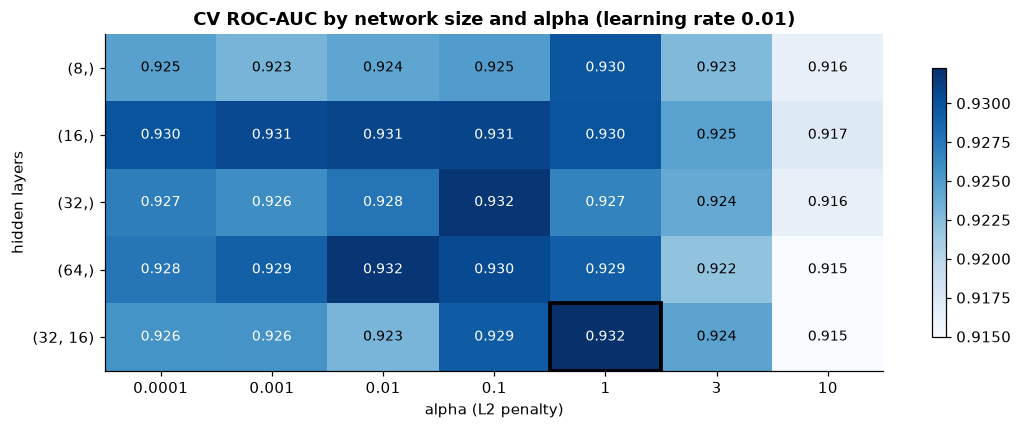

In [12]:
best_lr = best_params["learning_rate_init"]
heat = (grid[grid["learning rate"] == best_lr]
        .pivot_table(index="hidden layers", columns="alpha", values="mean_test_score"))
heat = heat.loc[[str(h) for h in param_grid["model__hidden_layer_sizes"]]]

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(heat.shape[1]), [f"{a:g}" for a in heat.columns])
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
lo, hi = np.nanmin(heat.values), np.nanmax(heat.values)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > lo + 0.6 * (hi - lo) else "black")
bi = list(heat.index).index(str(best_params["hidden_layer_sizes"]))
bj = list(heat.columns).index(best_params["alpha"])
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2.5))
ax.set_xlabel("alpha (L2 penalty)")
ax.set_ylabel("hidden layers")
ax.set_title(f"CV ROC-AUC by network size and alpha (learning rate {best_lr:g})")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### 3. Underfitting vs overfitting across `alpha`

Training vs CV ROC-AUC for the chosen network size. On the left (tiny penalty) the training score sits well above CV: the network memorizes. Too far right, both drop together: the penalty is so strong the network can't learn (underfitting). The best `alpha` is where CV peaks.

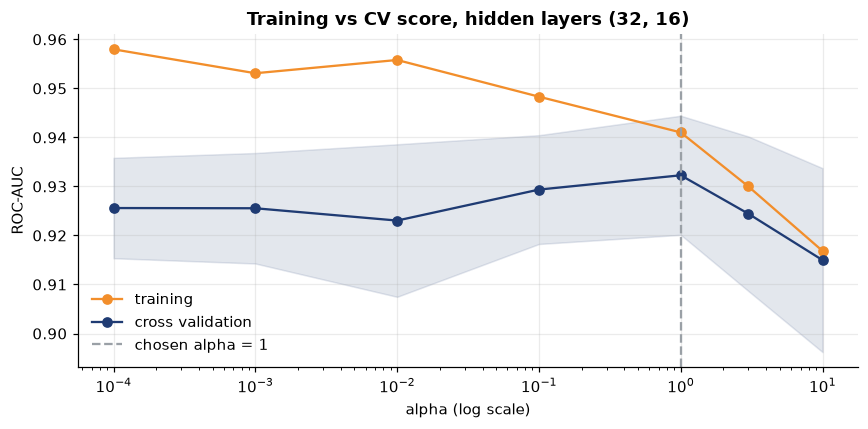

In [13]:
sub = (grid[(grid["learning rate"] == best_lr) &
            (grid["hidden layers"] == str(best_params["hidden_layer_sizes"]))]
       .sort_values("alpha"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sub["alpha"], sub["mean_train_score"], "o-", color=ORANGE, label="training")
ax.plot(sub["alpha"], sub["mean_test_score"], "o-", color=NAVY, label="cross validation")
ax.fill_between(sub["alpha"], sub["mean_test_score"] - sub["std_test_score"],
                sub["mean_test_score"] + sub["std_test_score"], color=NAVY, alpha=0.12)
ax.axvline(best_params["alpha"], color=GRAY, linestyle="--", label=f"chosen alpha = {best_params['alpha']:g}")
ax.set_xscale("log")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Training vs CV score, hidden layers {best_params['hidden_layer_sizes']}")
ax.legend()
plt.tight_layout()
plt.show()

### 4. ROC and precision-recall curves

Thin lines are the 5 folds, the thick line is all out-of-fold predictions together. The dot is the chosen threshold.

- **ROC**: the dashed diagonal is random guessing.
- **Precision-recall**: more useful when buyers are rare. The dashed line is the 15.5% buyer share, which is what random guessing gets.

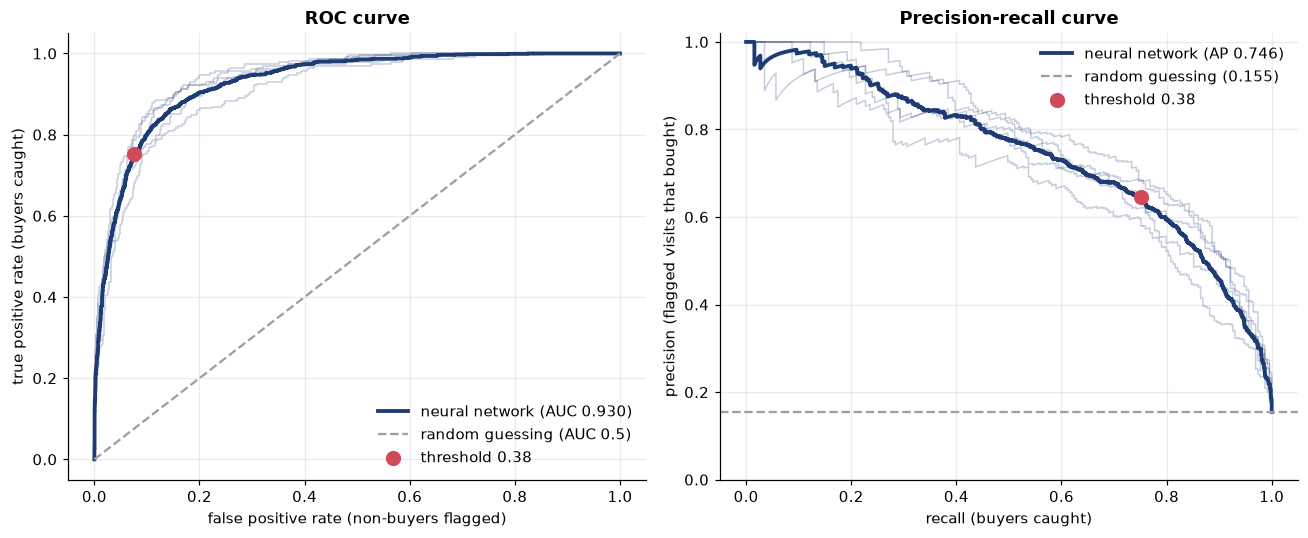

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
pred_best = oof_proba >= best_threshold
tpr_pt = recall_score(y_true, pred_best)
fpr_pt = ((pred_best == 1) & (y_true == 0)).sum() / (y_true == 0).sum()
prec_pt = precision_score(y_true, pred_best)

for k in range(1, 6):
    m = fold_id == k
    fpr, tpr, _ = roc_curve(y_true[m], oof_proba[m])
    ax1.plot(fpr, tpr, color=NAVY, alpha=0.25, linewidth=1)
    p, r, _ = precision_recall_curve(y_true[m], oof_proba[m])
    ax2.plot(r, p, color=NAVY, alpha=0.25, linewidth=1)

fpr, tpr, _ = roc_curve(y_true, oof_proba)
ax1.plot(fpr, tpr, color=NAVY, linewidth=2.5, label=f"neural network (AUC {roc_auc_score(y_true, oof_proba):.3f})")
ax1.plot([0, 1], [0, 1], "--", color=GRAY, label="random guessing (AUC 0.5)")
ax1.scatter([fpr_pt], [tpr_pt], s=80, color=RED, zorder=5, label=f"threshold {best_threshold:.2f}")
ax1.set_xlabel("false positive rate (non-buyers flagged)")
ax1.set_ylabel("true positive rate (buyers caught)")
ax1.set_title("ROC curve")
ax1.legend(loc="lower right")

p, r, _ = precision_recall_curve(y_true, oof_proba)
ax2.plot(r, p, color=NAVY, linewidth=2.5, label=f"neural network (AP {average_precision_score(y_true, oof_proba):.3f})")
ax2.axhline(BUYER_SHARE, linestyle="--", color=GRAY, label=f"random guessing ({BUYER_SHARE:.3f})")
ax2.scatter([tpr_pt], [prec_pt], s=80, color=RED, zorder=5, label=f"threshold {best_threshold:.2f}")
ax2.set_xlabel("recall (buyers caught)")
ax2.set_ylabel("precision (flagged visits that bought)")
ax2.set_ylim(0, 1.02)
ax2.set_title("Precision-recall curve")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 5. Choosing the threshold

Lowering the threshold catches more buyers (recall up) but flags more non-buyers (precision down). F1 balances the two and peaks at the chosen threshold.

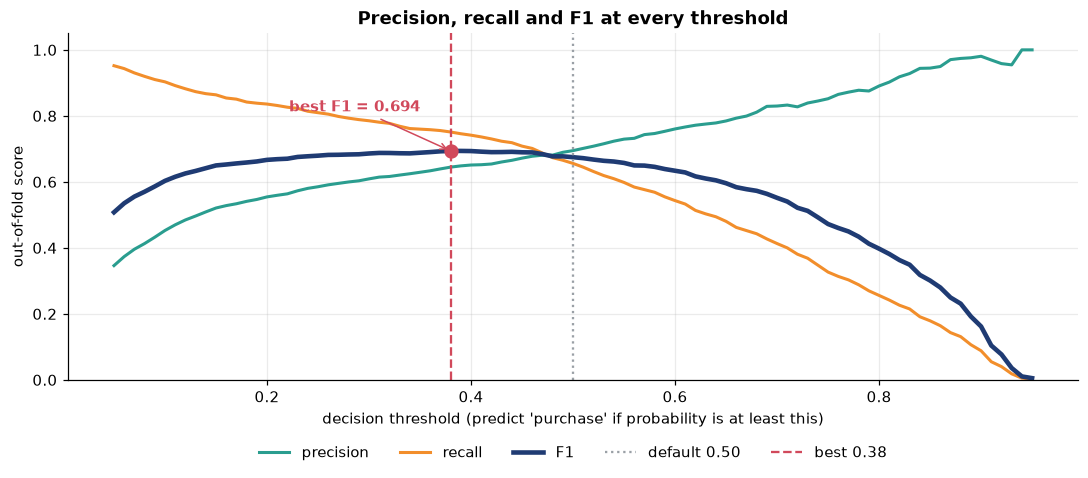

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve["threshold"], curve["precision"], color=TEAL, linewidth=2, label="precision")
ax.plot(curve["threshold"], curve["recall"], color=ORANGE, linewidth=2, label="recall")
ax.plot(curve["threshold"], curve["f1"], color=NAVY, linewidth=3, label="F1")
ax.axvline(0.5, color=GRAY, linestyle=":", label="default 0.50")
ax.axvline(best_threshold, color=RED, linestyle="--", label=f"best {best_threshold:.2f}")
best_f1 = curve["f1"].max()
ax.scatter([best_threshold], [best_f1], s=70, color=RED, zorder=5)
ax.annotate(f"best F1 = {best_f1:.3f}", xy=(best_threshold, best_f1), xytext=(best_threshold - 0.03, best_f1 + 0.12),
            ha="right", arrowprops={"arrowstyle": "->", "color": RED}, color=RED, fontweight="bold")
ax.set_xlabel("decision threshold (predict 'purchase' if probability is at least this)")
ax.set_ylabel("out-of-fold score")
ax.set_ylim(0, 1.05)
ax.set_title("Precision, recall and F1 at every threshold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5)
plt.tight_layout()
plt.show()

### 6. Confusion matrices

Counts and, in brackets, the share of each true class. The top row is non-buyers, the bottom row is buyers. The lower threshold catches more buyers (bottom right) at the cost of more false alarms (top right).

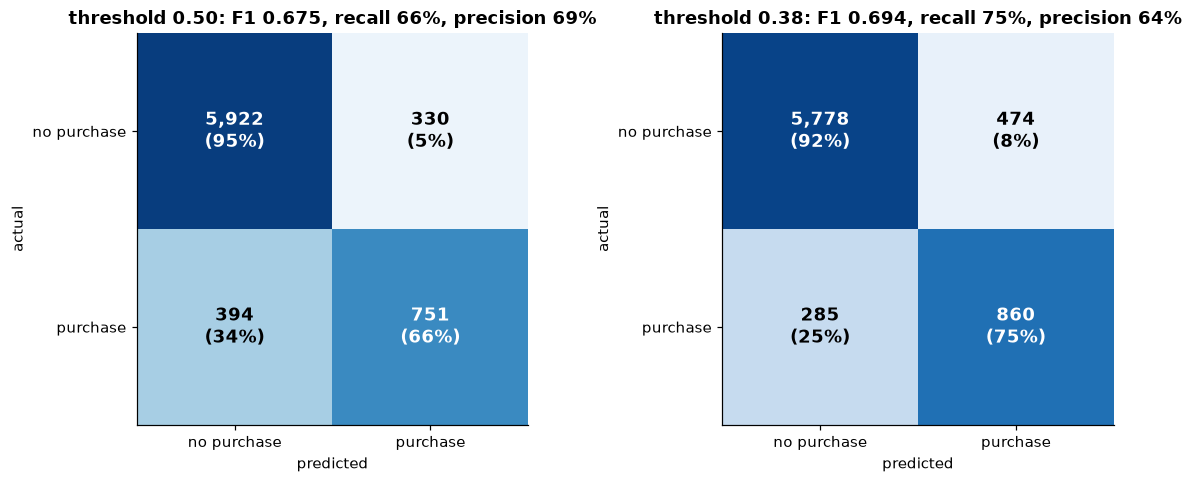

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
names = ["no purchase", "purchase"]
for ax, t in zip(axes, [0.5, best_threshold]):
    cm = confusion_matrix(y_true, oof_proba >= t)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=12,
                    color="white" if share[i, j] > 0.5 else "black", fontweight="bold")
    ax.set_xticks([0, 1], names)
    ax.set_yticks([0, 1], names)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    s = scores_at(t)
    ax.set_title(f"threshold {t:.2f}: F1 {s['f1']:.3f}, recall {s['recall']:.0%}, precision {s['precision']:.0%}")
plt.tight_layout()
plt.show()

### 7. How confident is the network?

Predicted purchase probability for real non-buyers (top) and real buyers (bottom). A good model pushes non-buyers toward 0 and buyers toward 1. Red bars are the mistakes at the chosen threshold: non-buyers flagged as buyers, and buyers that were missed.

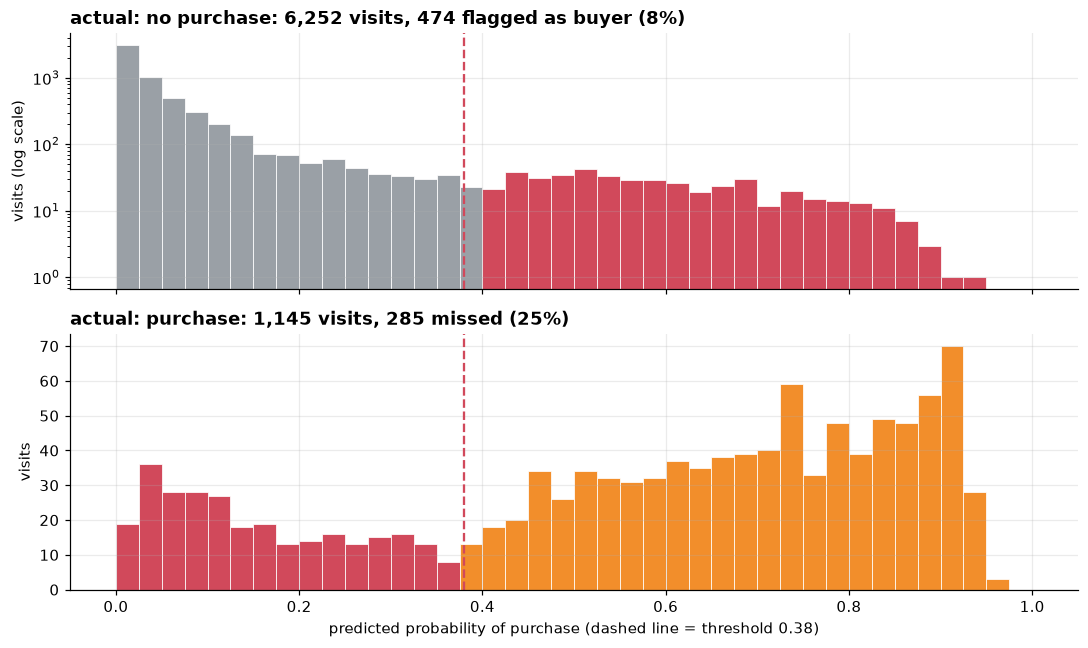

In [17]:
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
groups = [(0, "actual: no purchase", GRAY, "flagged as buyer"), (1, "actual: purchase", ORANGE, "missed")]
for ax, (cls, title, color, wrong_label) in zip(axes, groups):
    p = oof_proba[y_true == cls]
    counts, edges = np.histogram(p, bins=bins)
    wrong = (edges[:-1] >= best_threshold) if cls == 0 else (edges[1:] <= best_threshold)
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=np.where(wrong, RED, color),
           edgecolor="white", linewidth=0.5)
    ax.axvline(best_threshold, color=RED, linestyle="--", linewidth=1.5)
    n_wrong = (p >= best_threshold).sum() if cls == 0 else (p < best_threshold).sum()
    ax.set_title(f"{title}: {len(p):,} visits, {n_wrong:,} {wrong_label} ({n_wrong / len(p):.0%})", loc="left")
    ax.set_ylabel("visits")
axes[0].set_yscale("log")
axes[0].set_ylabel("visits (log scale)")
axes[1].set_xlabel(f"predicted probability of purchase (dashed line = threshold {best_threshold:.2f})")
plt.tight_layout()
plt.show()

### 8. Calibration

When the network says "30% chance of purchase", do about 30% of those visits buy? Points on the dashed diagonal mean the probabilities can be taken at face value. Visits are grouped into 10 equal-width probability ranges, and bigger dots hold more visits.

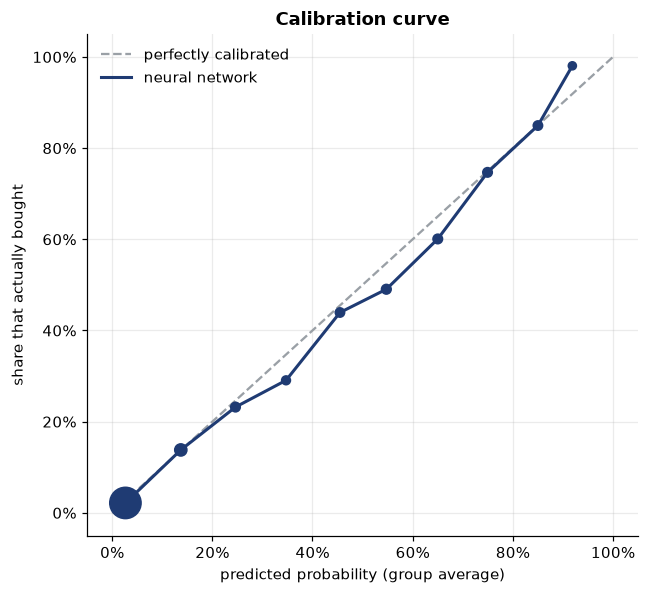

In [18]:
frac_pos, mean_pred = calibration_curve(y_true, oof_proba, n_bins=10, strategy="uniform")
bin_counts = np.histogram(oof_proba, bins=np.linspace(0, 1, 11))[0]
bin_counts = bin_counts[bin_counts > 0]

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "--", color=GRAY, label="perfectly calibrated")
ax.plot(mean_pred, frac_pos, "-", color=NAVY, linewidth=2, label="neural network")
ax.scatter(mean_pred, frac_pos, s=20 + 400 * bin_counts / bin_counts.max(), color=NAVY, zorder=5)
ax.set_xlabel("predicted probability (group average)")
ax.set_ylabel("share that actually bought")
ax.set_title("Calibration curve")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 9. Learning curve

Training vs CV ROC-AUC as the network sees more training rows.
- If the two lines are far apart, more data would help (overfitting).
- If they meet low, the model is too simple (underfitting).
- If they meet high and flatten, the model has learned about as much as this data allows.

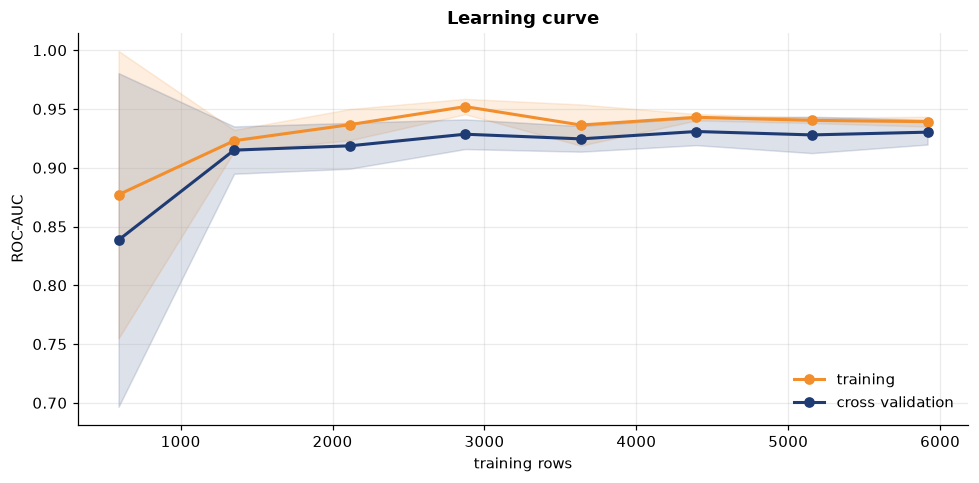

Gap at full size: 0.009 ROC-AUC


In [19]:
sizes, tr_scores, cv_scores = learning_curve(
    best_pipe, X_train, y_train, cv=cv, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE,
)

fig, ax = plt.subplots(figsize=(9, 4.5))
for scores, color, label in [(tr_scores, ORANGE, "training"), (cv_scores, NAVY, "cross validation")]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, "o-", color=color, linewidth=2, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.15)
ax.set_xlabel("training rows")
ax.set_ylabel("ROC-AUC")
ax.set_title("Learning curve")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Gap at full size: {tr_scores[-1].mean() - cv_scores[-1].mean():.3f} ROC-AUC")

### 10. Training curve

The tuned network trained once on all training rows. Left: the error on the rows it learns from, per pass over the data (epoch). Right: accuracy on the 10% that early stopping holds back. Training stops after 10 epochs with no improvement, and the network keeps the weights from its best epoch. The swings on the right are small (about one percentage point).

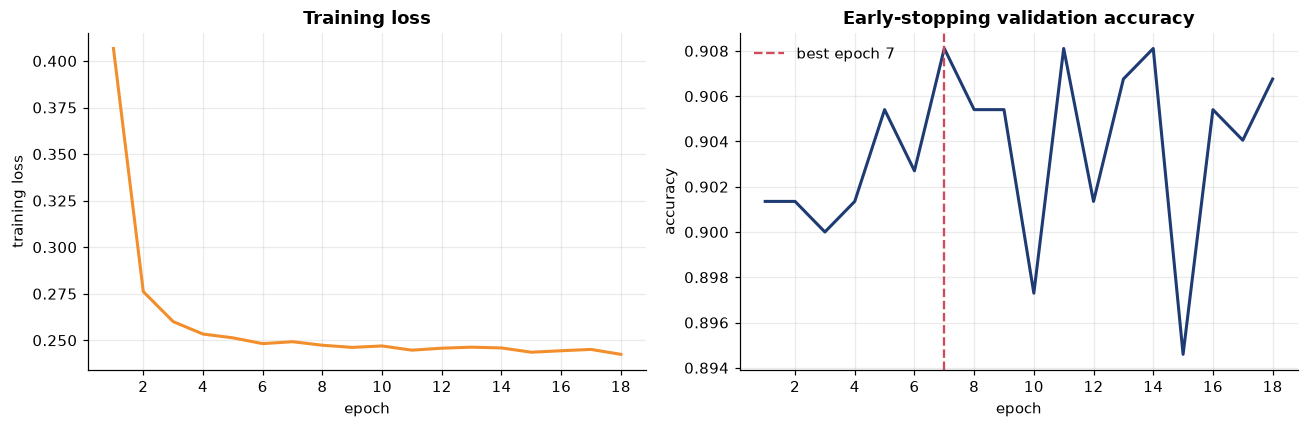

Stopped after 18 epochs


In [20]:
final_fit = clone(best_pipe).fit(X_train, y_train)
net = final_fit.named_steps["model"]
best_epoch = int(np.argmax(net.validation_scores_)) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs = np.arange(1, len(net.loss_curve_) + 1)
ax1.plot(epochs, net.loss_curve_, color=ORANGE, linewidth=2)
ax1.set_xlabel("epoch")
ax1.set_ylabel("training loss")
ax1.set_title("Training loss")
ax2.plot(epochs, net.validation_scores_, color=NAVY, linewidth=2)
ax2.axvline(best_epoch, color=RED, linestyle="--", label=f"best epoch {best_epoch}")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.set_title("Early-stopping validation accuracy")
ax2.legend()
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

print(f"Stopped after {net.n_iter_} epochs")

### 11. What the network relies on

A network has no simple coefficients to read, so this uses **permutation importance**: shuffle one column in a fold's scoring rows and measure how much ROC-AUC drops. A big drop means the network leans on that column. Averaged over the 5 folds, using each fold's own model.

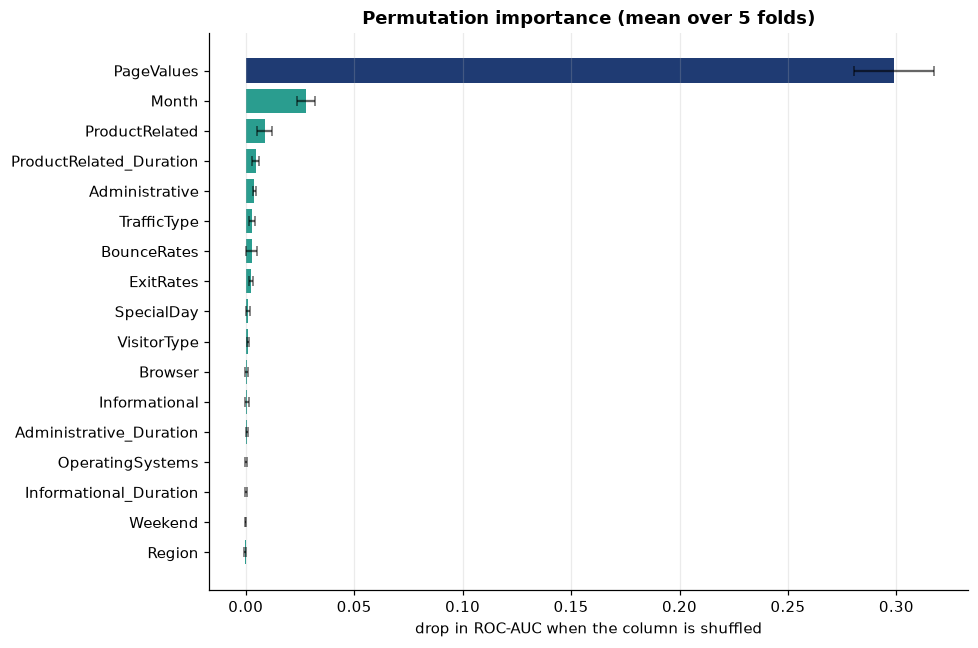

In [21]:
drops = []
for m, va in fold_models:
    pi = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring="roc_auc",
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    drops.append(pi.importances_mean)
drops = pd.DataFrame(drops, columns=X_train.columns)
imp = pd.DataFrame({"mean": drops.mean(), "std": drops.std()}).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 6))
colors = [NAVY if c == imp.index[-1] else TEAL for c in imp.index]
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=colors, capsize=3, error_kw={"alpha": 0.6})
ax.set_xlabel("drop in ROC-AUC when the column is shuffled")
ax.set_title("Permutation importance (mean over 5 folds)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Who gets missed?

Most visits with `PageValues = 0` never buy, so a buyer with `PageValues = 0` looks like a non-buyer to the network.

In [22]:
pv_zero = (X_train["PageValues"] == 0).to_numpy()
missed = (y_true == 1) & (oof_proba < best_threshold)

print(f"Buy rate when PageValues = 0: {y_true[pv_zero].mean():.1%}")
print(f"Buy rate when PageValues > 0: {y_true[~pv_zero].mean():.1%}")
print(f"Missed buyers: {missed.sum():,}, of which {(missed & pv_zero).sum():,} "
      f"({(missed & pv_zero).sum() / missed.sum():.0%}) have PageValues = 0")

Buy rate when PageValues = 0: 3.5%
Buy rate when PageValues > 0: 57.8%
Missed buyers: 285, of which 199 (70%) have PageValues = 0


---
## Takeaways

- **The network beats the baseline by a wide margin.** CV ROC-AUC 0.93 and PR-AUC 0.75, compared with 0.50 and 0.15 for always guessing "no purchase". Accuracy only moves from 85% to 90%, which is why it is not the main score.
- **Tuning helped a little.** F1 went from 0.64 (default) to 0.67. Most settings in the grid land between 0.92 and 0.93 ROC-AUC, so the network is not very sensitive to its size. Only a very heavy penalty (`alpha = 10`) clearly hurts. The chosen network is two layers (32 and 16 neurons) with `alpha = 1`.
- **Lowering the threshold to 0.38 raises F1 to 0.69.** It catches 75% of buyers instead of 66%, while 64% of flagged visits really buy (down from 69%).
- **Little overfitting.** Training F1 is only about 0.02 above CV F1, and in the learning curve the training and CV lines meet and flatten after about 3,000 rows. More rows of the same data would probably not help much. Better features would.
- **Probabilities can be trusted.** The calibration curve sits close to the diagonal.
- **`PageValues` does most of the work.** Shuffling it drops ROC-AUC by about 0.30, far more than any other column. `Month` and `ProductRelated` come next. Most buyers the network misses have `PageValues = 0` (see above).
- **Next:** score the hold-out once the team has picked its final model across all 8 models.

---
## Summary for the team comparison

In [23]:
tuned = pd.DataFrame(results).set_index("model").loc["Neural network, tuned"]
at_t = scores_at(best_threshold)

summary = pd.Series({
    "settings": str(best_params),
    "CV ROC-AUC": round(tuned["roc_auc"], 3),
    "CV PR-AUC": round(tuned["pr_auc"], 3),
    "CV F1 @ 0.5": round(tuned["f1"], 3),
    "train F1 @ 0.5": round(tuned["train f1"], 3),
    "best threshold": best_threshold,
    "CV F1 @ best threshold": round(at_t["f1"], 3),
    "recall @ best threshold": round(at_t["recall"], 3),
    "precision @ best threshold": round(at_t["precision"], 3),
}, name="Neural network (MLP)")
summary.to_frame()

,Neural network (MLP)
settings,"{'alpha': 1.0, 'hidden_layer_sizes': (32, 16),..."
CV ROC-AUC,0.932
CV PR-AUC,0.751
CV F1 @ 0.5,0.674
train F1 @ 0.5,0.697
best threshold,0.38
CV F1 @ best threshold,0.694
recall @ best threshold,0.751
precision @ best threshold,0.645
